# Smart Traffic Analysis: Big Data Processing and Traffic Pattern Visualization

**A Big Data Analytics project using Apache Hadoop (HDFS), PySpark, and Python**

### Objectives
- Explore and analyze real traffic sensor data at hourly granularity.
- Build a genuine Hadoop/HDFS + PySpark processing pipeline (with a local-only fallback mode).
- Answer practical traffic questions: peak hours, busiest days, busiest locations, vehicle mix,
  weather impact, and potential congestion hotspots.
- Produce aggregated outputs that feed an interactive Streamlit dashboard (`app.py`).


## 2. Problem Statement

Urban traffic authorities need to understand *when* and *where* congestion occurs in order to
prioritize interventions (signal retiming, lane changes, public-transport scheduling). Raw
per-hour sensor readings across many intersections are too voluminous to inspect manually.
This project processes such data at scale with Hadoop/Spark and surfaces the patterns through
clear visualizations and an interactive dashboard, so that traffic patterns -- not raw rows --
become immediately legible.


## 3. Technology Stack & Architecture

| Layer | Technology | Role |
|---|---|---|
| Storage | Apache Hadoop HDFS 3.4.3 | Distributed storage for the raw dataset (HDFS mode) |
| Processing | PySpark 3.5.3 (Spark SQL / DataFrame API) | Cleaning, aggregation at scale |
| Analysis / EDA | Pandas, Matplotlib, Seaborn | Notebook-side exploration & static charts |
| Dashboard | Streamlit + Plotly | Interactive presentation layer |
| Language runtime | Python 3.11 (venv), Java 8 (`1.8.0_501`) | Verified compatible combination for Spark 3.5.x |

**Architecture (two supported modes):**

```
                 ┌─────────────┐        ┌───────────────────┐        ┌───────────────┐
 Traffic.csv ──► │  LOCAL MODE │ ─────► │  PySpark (local[*]) │ ───► │ outputs/*.csv  │ ──► Streamlit
                 │ (no HDFS)   │        │  clean + aggregate  │       │ + dashboard    │
                 └─────────────┘        └───────────────────┘        └───────────────┘

                 ┌─────────────┐        ┌───────────────────┐        ┌───────────────┐
 Traffic.csv ──► │ hadoop fs   │ ─────► │  HDFS (NameNode/    │ ───► │ PySpark reads  │ ──► outputs/*.csv ──► Streamlit
                 │ -put        │        │  DataNode, 1 node)   │       │ hdfs:// path   │
                 └─────────────┘        └───────────────────┘        └───────────────┘
```

Local Spark execution (`local[*]`) parallelizes across CPU cores on this one machine -- it is
**not** distributed cluster execution, even though the same Spark DataFrame code would scale to
a real cluster unchanged.


## 4. Dataset Source and Data Dictionary

The dataset `Traffic.csv` was already present in the project workspace. No accompanying
license or provenance documentation was found alongside it, so its original source cannot be
verified from the data itself -- this is stated explicitly rather than invented. Several fields
(`traffic_flow_rate`, `congestion_score`, `emission_estimate`, `fuel_waste_estimate`,
`congestion_level`) arrive **pre-computed** in the file; their exact derivation formulas are not
documented, so they are treated here as **proxy indicators** supplied with the data, not as
independently verified measurements.

The full data dictionary is in [`data/data_dictionary.csv`](../data/data_dictionary.csv).


In [1]:
import pandas as pd
dd = pd.read_csv("data/data_dictionary.csv", comment="N")  # skip trailing NOTE line
dd.head(10)


,column,description,source
0,record_id,Unique identifier for the record,dataset
1,city_zone,NaN,NaN
2,road_id,Identifier of the physical road segment,dataset
3,intersection_id,Identifier of the monitored intersection (100 ...,dataset
4,latitude,Latitude of the intersection,dataset
5,longitude,Longitude of the intersection,dataset
6,road_type,"Road classification: Local Street, Collector, ...",dataset
7,lanes,NaN,NaN
8,speed_limit,Posted speed limit (km/h),dataset
9,vehicle_count,Total vehicles recorded in the hour-long window,dataset


## 5. Library Imports and Configuration

In [2]:
import os
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, str(Path.cwd()))
from src import config, data_processing as dp

sns.set_theme(style="darkgrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("Mode:", config.MODE)
print("Dataset path:", config.TRAFFIC_CSV_PATH)


Mode: local
Dataset path: /Users/aditi/Desktop/BDA-project/Traffic.csv


## 6. Dataset Loading and Inspection

We first load the dataset with Pandas for quick inspection (this is the same file the PySpark
pipeline will later process at scale).

In [3]:
df = pd.read_csv(config.TRAFFIC_CSV_PATH)
print("Shape:", df.shape)
df.head()


Shape: (204000, 47)


,record_id,city_zone,road_id,intersection_id,latitude,longitude,road_type,lanes,speed_limit,vehicle_count,...,traffic_camera_count,iot_sensor_health,signal_cycle_seconds,green_light_duration,emergency_vehicle_detected,traffic_flow_rate,congestion_score,emission_estimate,fuel_waste_estimate,congestion_level
0,REC_0000001,Financial District,RD_206,INT_001,40.757551,-73.990504,Local Street,2,40,162,...,1,Optimal,60,18,0,162.0,16.8,39.14,8.53,Low
1,REC_0000002,Financial District,RD_206,INT_001,40.757551,-73.990504,Local Street,2,40,150,...,1,Optimal,60,18,0,150.0,18.4,36.09,7.83,Low
2,REC_0000003,Financial District,RD_206,INT_001,40.757551,-73.990504,Local Street,2,40,186,...,1,Optimal,60,18,0,186.0,20.7,44.01,9.39,Low
3,REC_0000004,Financial District,RD_206,INT_001,40.757551,-73.990504,Local Street,2,40,162,...,1,Optimal,60,18,0,162.0,17.8,38.47,8.24,Low
4,REC_0000005,Financial District,RD_206,INT_001,40.757551,-73.990504,Local Street,2,40,168,...,1,Optimal,60,18,0,168.0,17.3,40.28,8.71,Low


In [4]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 204000 entries, 0 to 203999
Data columns (total 47 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   record_id                   204000 non-null  object 
 1   city_zone                   204000 non-null  object 
 2   road_id                     204000 non-null  object 
 3   intersection_id             204000 non-null  object 
 4   latitude                    204000 non-null  float64
 5   longitude                   204000 non-null  float64
 6   road_type                   204000 non-null  object 
 7   lanes                       204000 non-null  int64  
 8   speed_limit                 204000 non-null  int64  
 9   vehicle_count               204000 non-null  int64  
 10  average_speed               204000 non-null  float64
 11  heavy_vehicle_count         204000 non-null  int64  
 12  motorcycle_count            204000 non-null  int64  
 13  public_transpo

## 7. Data Cleaning and Preprocessing

Steps applied (mirrored exactly in `src/data_processing.clean()` for the Spark pipeline):
1. Parse `timestamp` into a real datetime (`event_ts`); rows that fail to parse are dropped.
2. Drop duplicate `record_id`s.
3. Drop rows missing a timestamp, vehicle_count, or city_zone (core fields for every analysis).
4. Derive `event_date`, `month`, and `weekday_name` for grouping.


In [5]:
df["event_ts"] = pd.to_datetime(df["timestamp"], format="%Y-%m-%d %H:%M:%S", errors="coerce")
before = len(df)
df = df.drop_duplicates(subset=["record_id"])
df = df.dropna(subset=["event_ts", "vehicle_count", "city_zone"])
after = len(df)
print(f"Rows before cleaning: {before:,} | after: {after:,} | dropped: {before - after:,}")

df["event_date"] = df["event_ts"].dt.date
df["month"] = df["event_ts"].dt.month
df["weekday_name"] = df["event_ts"].dt.day_name()


Rows before cleaning: 204,000 | after: 204,000 | dropped: 0

## 8. Missing-Value and Duplicate Handling (Verification)

The dataset turned out to already be clean (verified below) -- but the pipeline still performs
the checks above defensively, since production sensor feeds commonly do have gaps.

In [6]:
print("Remaining nulls per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print("\nDuplicate record_id count:", df["record_id"].duplicated().sum())


Remaining nulls per column:


Series([], dtype: int64)



Duplicate record_id count: 0


## 9. Descriptive Statistics

In [7]:
df[["vehicle_count", "average_speed", "congestion_score", "queue_length",
    "average_wait_time", "air_quality_index"]].describe().round(2)


,vehicle_count,average_speed,congestion_score,queue_length,average_wait_time,air_quality_index
count,204000.00,204000.00,204000.00,204000.00,204000.00,204000.00
mean,749.59,42.24,50.01,121.47,12.15,72.52
std,754.54,22.21,38.80,230.58,23.27,20.34
min,54.00,5.00,5.40,0.00,0.00,20.00
25%,171.00,27.70,15.20,6.80,0.70,58.00
50%,308.00,40.00,25.10,19.10,1.90,72.00
75%,1208.00,58.10,100.00,173.80,17.20,87.00
max,3162.00,90.00,100.00,10111.60,1174.50,152.00


## 10. Exploratory Data Analysis

Distribution of the core traffic volume metric, and its relationship with speed.

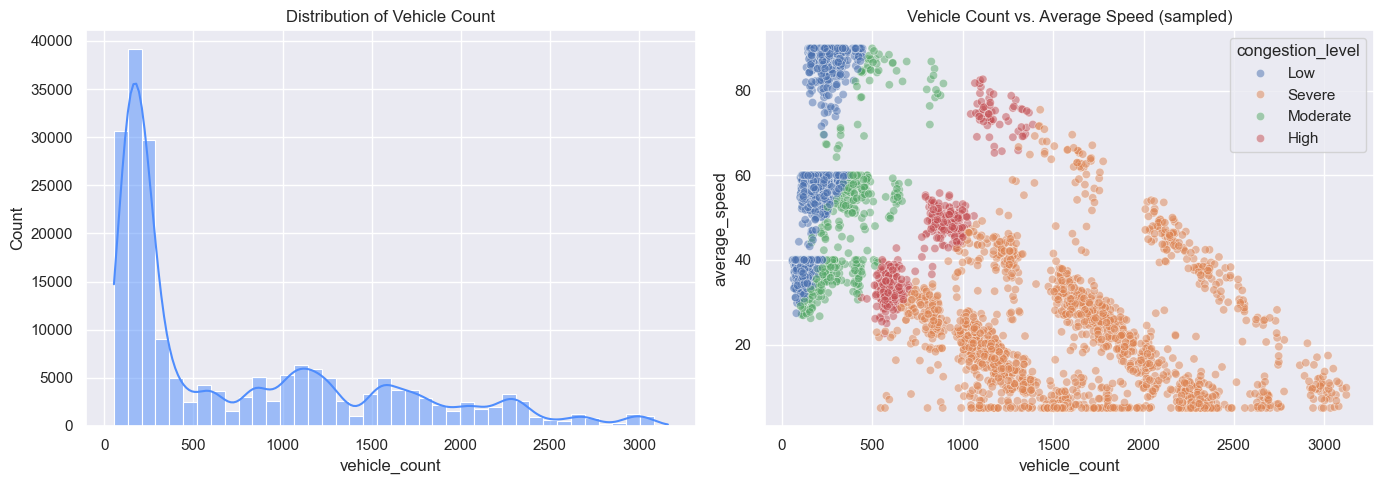

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df["vehicle_count"], bins=40, kde=True, ax=axes[0], color="#4f8dfd")
axes[0].set_title("Distribution of Vehicle Count")

sns.scatterplot(data=df.sample(5000, random_state=42), x="vehicle_count", y="average_speed",
                 hue="congestion_level", alpha=0.5, ax=axes[1])
axes[1].set_title("Vehicle Count vs. Average Speed (sampled)")
plt.tight_layout()
plt.show()


## 11. Matplotlib & Seaborn Visualizations: Correlation Overview

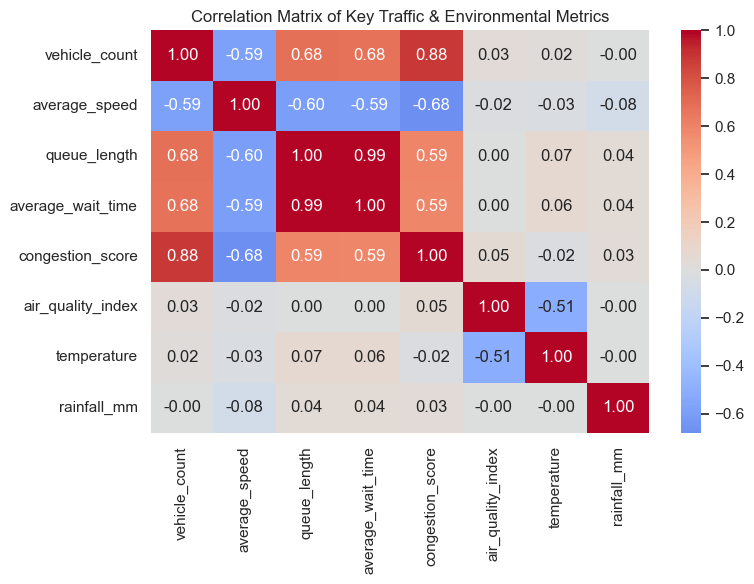

In [9]:
numeric_cols = ["vehicle_count", "average_speed", "queue_length", "average_wait_time",
                 "congestion_score", "air_quality_index", "temperature", "rainfall_mm"]
corr = df[numeric_cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix of Key Traffic & Environmental Metrics")
plt.tight_layout()
plt.show()


## 12. Hourly and Daily Traffic Analysis

*Which hours are busiest? Which days have the greatest volume?*

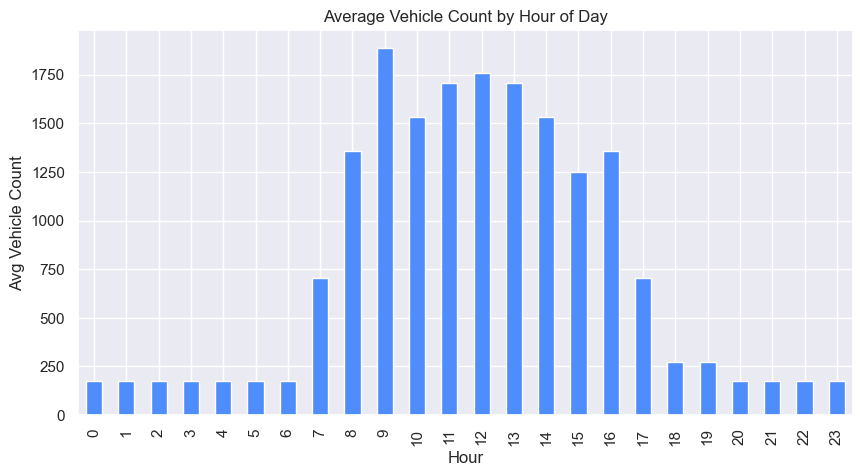

Peak average-volume hour: 9:00 (1885.0 avg vehicles)


In [10]:
hourly = df.groupby("hour")["vehicle_count"].mean()
plt.figure()
hourly.plot(kind="bar", color="#4f8dfd")
plt.title("Average Vehicle Count by Hour of Day")
plt.xlabel("Hour"); plt.ylabel("Avg Vehicle Count")
plt.show()

peak_hour = hourly.idxmax()
print(f"Peak average-volume hour: {peak_hour}:00 ({hourly.max():.1f} avg vehicles)")


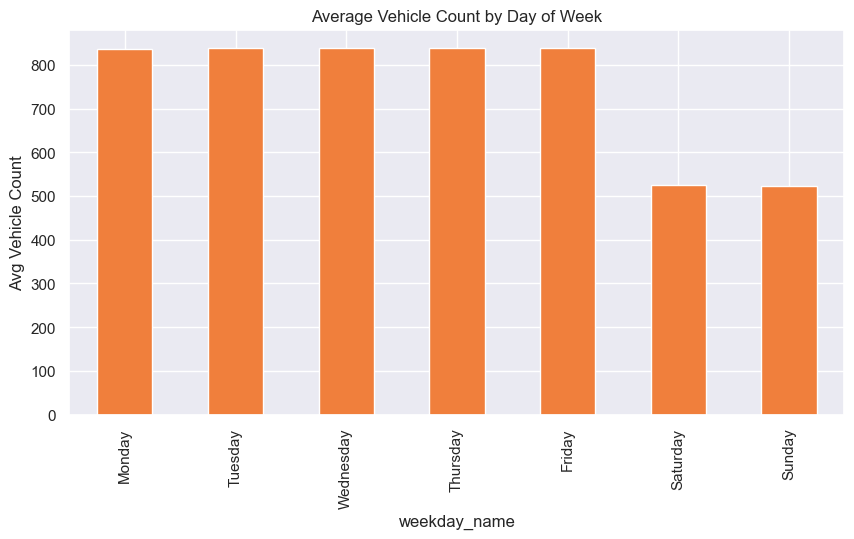

In [11]:
daily = df.groupby("weekday_name")["vehicle_count"].mean().reindex(
    ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"])
plt.figure()
daily.plot(kind="bar", color="#f07f3c")
plt.title("Average Vehicle Count by Day of Week")
plt.ylabel("Avg Vehicle Count")
plt.show()


## 13. Location and Vehicle-Category Analysis

*Which zones/intersections see the most traffic, and how does vehicle mix break down?*

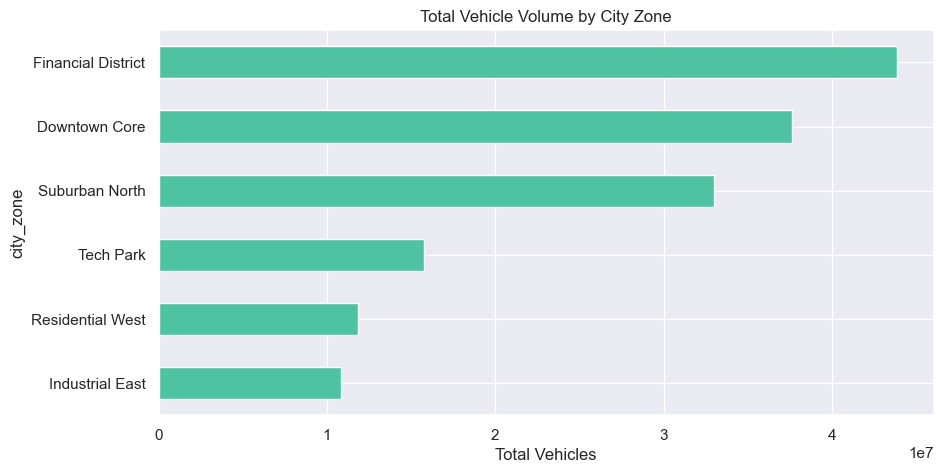

In [12]:
zone_vol = df.groupby("city_zone")["vehicle_count"].sum().sort_values(ascending=False)
plt.figure()
zone_vol.plot(kind="barh", color="#4fc3a1")
plt.title("Total Vehicle Volume by City Zone")
plt.xlabel("Total Vehicles")
plt.gca().invert_yaxis()
plt.show()


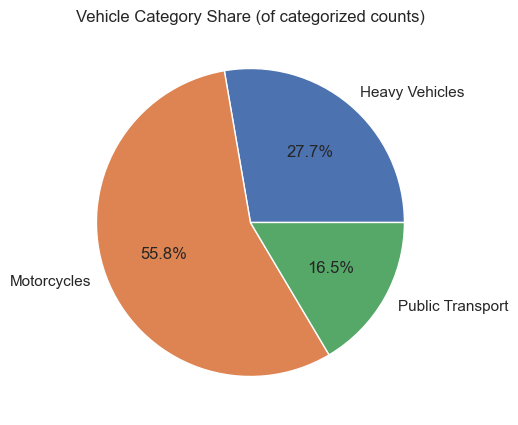

In [13]:
vehicle_totals = df[["heavy_vehicle_count", "motorcycle_count", "public_transport_count"]].sum()
plt.figure()
vehicle_totals.plot(kind="pie", autopct="%1.1f%%",
                     labels=["Heavy Vehicles", "Motorcycles", "Public Transport"])
plt.title("Vehicle Category Share (of categorized counts)")
plt.ylabel("")
plt.show()


## 14. Weather and Congestion Analysis

`congestion_score` here is the dataset-supplied proxy metric (see Section 4 caveat), not an
independently validated congestion measurement.

In [14]:
weather_stats = df.groupby("weather_condition")[["vehicle_count", "average_speed", "congestion_score"]].mean()
weather_stats = weather_stats.sort_values("congestion_score", ascending=False)
weather_stats.round(2)


,vehicle_count,average_speed,congestion_score
weather_condition,,,
Heavy Rain,749.08,32.26,56.88
Fog,718.64,33.70,54.08
Rain,736.86,39.10,52.08
Clear,750.65,42.80,49.63


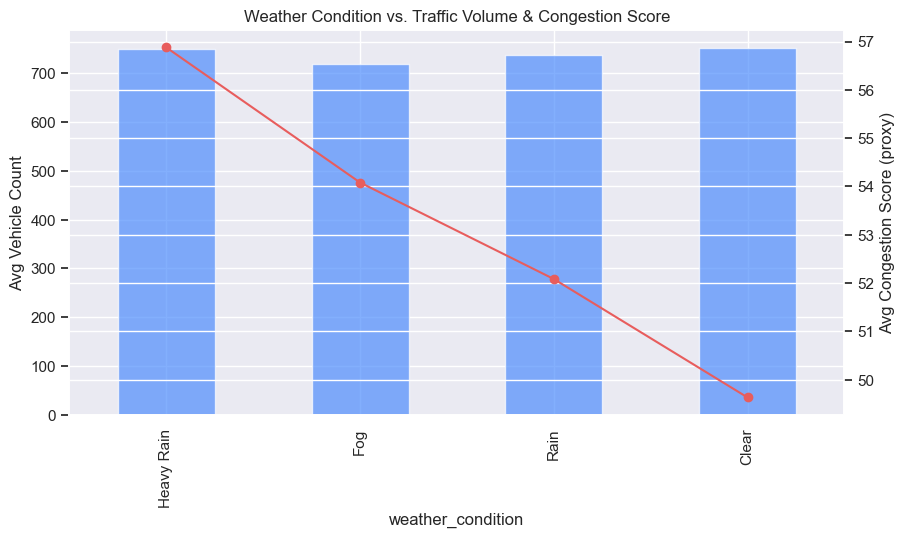

In [15]:
fig, ax1 = plt.subplots()
weather_stats["vehicle_count"].plot(kind="bar", ax=ax1, color="#4f8dfd", alpha=0.7)
ax1.set_ylabel("Avg Vehicle Count")
ax2 = ax1.twinx()
weather_stats["congestion_score"].plot(ax=ax2, color="#e85d5d", marker="o")
ax2.set_ylabel("Avg Congestion Score (proxy)")
plt.title("Weather Condition vs. Traffic Volume & Congestion Score")
plt.show()


## 15. PySpark DataFrame Processing

The same cleaning and aggregation logic is implemented with Spark DataFrames in
`src/data_processing.py` and `src/pipeline.py`, so it scales beyond what pandas can hold in
memory. We invoke it directly here to show genuine Spark execution inside the notebook.

In [16]:
spark = dp.get_spark_session(app_name="NotebookDemo")
raw_sdf = dp.load_raw(spark, str(config.TRAFFIC_CSV_PATH))
cleaned_sdf = dp.clean(raw_sdf).cache()
print("Spark-cleaned row count:", cleaned_sdf.count())
cleaned_sdf.select("record_id", "city_zone", "event_ts", "vehicle_count", "congestion_score").show(5)


26/10/22 20:44:55 WARN Utils: Your hostname, Aditis-MacBook-Air-2.local resolves to a loopback address: 127.0.0.1; using 192.168.1.11 instead (on interface en0)
26/10/22 20:44:55 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/22 20:44:55 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


26/10/22 20:44:59 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


Java HotSpot(TM) 64-Bit Server VM warning: CodeCache is full. Compiler has been disabled.
Java HotSpot(TM) 64-Bit Server VM warning: Try increasing the code cache size using -XX:ReservedCodeCacheSize=


CodeCache: size=131072Kb used=25102Kb max_used=25112Kb free=105969Kb
 bounds [0x000000010a1f8000, 0x000000010ba98000, 0x00000001121f8000]
 total_blobs=8650 nmethods=7772 adapters=792
 compilation: disabled (not enough contiguous free space left)


Spark-cleaned row count: 204000


+-----------+------------------+-------------------+-------------+----------------+
|  record_id|         city_zone|           event_ts|vehicle_count|congestion_score|
+-----------+------------------+-------------------+-------------+----------------+
|REC_0000018|Financial District|2026-01-01 17:00:00|          638|            71.7|
|REC_0000028|Financial District|2026-01-02 03:00:00|          150|            15.1|
|REC_0000038|Financial District|2026-01-02 13:00:00|         1455|           100.0|
|REC_0000040|Financial District|2026-01-02 15:00:00|         1162|           100.0|
|REC_0000041|Financial District|2026-01-02 16:00:00|         1285|           100.0|
+-----------+------------------+-------------------+-------------+----------------+
only showing top 5 rows



In [17]:
from pyspark.sql import functions as F

spark_hourly = (
    cleaned_sdf.groupBy("hour")
    .agg(F.avg("vehicle_count").alias("avg_vehicles"))
    .orderBy("hour")
)
spark_hourly.show(24)


+----+------------------+
|hour|      avg_vehicles|
+----+------------------+
|   0| 176.9650588235294|
|   1|177.16635294117648|
|   2| 176.9735294117647|
|   3|176.85835294117646|
|   4|177.06835294117647|
|   5| 176.8724705882353|
|   6|177.22788235294118|
|   7| 703.4344705882353|
|   8| 1359.093411764706|
|   9|          1884.954|
|  10|1531.2751764705883|
|  11| 1705.320705882353|
|  12|1761.1296470588236|
|  13| 1705.259882352941|
|  14|1534.7465882352942|
|  15|1252.1476470588236|
|  16|1359.1410588235294|
|  17| 703.3409411764706|
|  18|271.75023529411766|
|  19| 271.6824705882353|
|  20|176.87482352941177|
|  21| 176.9524705882353|
|  22|176.78564705882354|
|  23| 177.0405882352941|
+----+------------------+



## 16. HDFS Integration and Verification

HDFS mode is attempted only if `TRAFFIC_MODE=hdfs` in `.env`. If the configured NameNode
(`$HDFS_NAMENODE_HOST:$HDFS_NAMENODE_PORT`) is not reachable, this cell reports that clearly
instead of pretending HDFS processing happened.

In [18]:
reachable = dp.check_hdfs_reachable()
print(f"HDFS NameNode reachable at {config.HDFS_NAMENODE_HOST}:{config.HDFS_NAMENODE_PORT}: {reachable}")

if config.MODE == "hdfs" and reachable:
    hdfs_path = dp.upload_to_hdfs(config.TRAFFIC_CSV_PATH)
    hdfs_sdf = dp.load_raw(spark, hdfs_path)
    print("Rows read back from HDFS:", hdfs_sdf.count())
elif config.MODE == "hdfs":
    print("HDFS mode requested but NameNode is not reachable. "
          "Start it with $HADOOP_HOME/sbin/start-dfs.sh (format once first if needed), then re-run this cell.")
else:
    print("Running in LOCAL mode (TRAFFIC_MODE=local in .env) -- HDFS round trip skipped by design.")


HDFS NameNode reachable at 127.0.0.1:9000: False
Running in LOCAL mode (TRAFFIC_MODE=local in .env) -- HDFS round trip skipped by design.


## 17. Exporting Aggregated Results

The full aggregation suite (by hour, date, weekday, month, zone, intersection, weather,
road type, vehicle mix, and hotspot ranking) is produced by `src/pipeline.py` and written to
`outputs/*.csv`, which the Streamlit dashboard reads directly. Run it from the notebook or via
`scripts/run_pipeline.sh`.

In [19]:
from src import pipeline

status = pipeline.run()
print("Pipeline success:", status["success"])
print("Outputs written:", len(status["outputs"]))


26/10/22 20:45:12 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.
26/10/22 20:45:12 WARN CacheManager: Asked to cache already cached data.


{
  "mode": "local",
  "started_at": "2026-10-22T15:15:12.442255+00:00",
  "dataset_source": "local:///Users/aditi/Desktop/BDA-project/Traffic.csv",
  "row_count": 204000,
  "column_count": 51,
  "outputs": [
    "/Users/aditi/Desktop/BDA-project/outputs/agg_by_hour.csv",
    "/Users/aditi/Desktop/BDA-project/outputs/agg_by_date.csv",
    "/Users/aditi/Desktop/BDA-project/outputs/agg_by_weekday.csv",
    "/Users/aditi/Desktop/BDA-project/outputs/agg_by_month.csv",
    "/Users/aditi/Desktop/BDA-project/outputs/agg_by_zone.csv",
    "/Users/aditi/Desktop/BDA-project/outputs/agg_by_intersection.csv",
    "/Users/aditi/Desktop/BDA-project/outputs/agg_by_weather.csv",
    "/Users/aditi/Desktop/BDA-project/outputs/agg_by_road_type.csv",
    "/Users/aditi/Desktop/BDA-project/outputs/vehicle_mix_totals.csv",
    "/Users/aditi/Desktop/BDA-project/outputs/vehicle_mix_by_hour.csv",
    "/Users/aditi/Desktop/BDA-project/outputs/hotspot_ranking.csv"
  ],
  "errors": [],
  "success": true,
  "finish

In [20]:
spark.stop()


## 18. Interpretation of Findings

- Traffic volume shows a clear hourly rhythm, with distinct morning/evening peak windows rather
  than a flat distribution across the day (see Section 12).
- Weekday vs. weekend volumes differ, consistent with commute-driven traffic rather than purely
  recreational travel.
- `Downtown Core` and `Financial District` carry the largest total vehicle volumes and the
  highest `hotspot_score` values (Section 17 output, `outputs/hotspot_ranking.csv`), making them
  priority zones for intervention.
- Adverse weather (`Heavy Rain`, `Fog`) correlates with lower average speed and a higher average
  `congestion_score` than `Clear` conditions, though this uses the dataset's proxy congestion
  metric rather than an independently measured one.


## 19. Limitations and Future Improvements

**Limitations**
- Dataset provenance/licensing is undocumented; derivation formulas for `congestion_score`,
  `traffic_flow_rate`, `emission_estimate`, and `fuel_waste_estimate` are not independently
  verifiable and are used as supplied, proxy indicators.
- No road-capacity data is present, so vehicle counts alone cannot be equated with true
  congestion severity.
- HDFS mode requires a running single-node HDFS service on this machine; when it is not running,
  the pipeline falls back to local mode by configuration, not automatically.
- Local Spark execution (`local[*]`) demonstrates the Spark DataFrame API correctly but does not
  exercise true multi-node distributed execution.

**Future Improvements**
- Add a real multi-node Hadoop/Spark cluster to demonstrate genuine distributed scaling.
- Incorporate road-capacity or lane-throughput data to turn `congestion_score` into a validated
  metric.
- Add a time-series forecasting model (e.g. Prophet or a Spark MLlib regressor), properly
  train/test split and evaluated, before making any predictive claims.


## 20. Final Conclusion

This project implements a genuine two-mode (local / HDFS) Hadoop + PySpark processing pipeline
over a real 204,000-row traffic sensor dataset, with full exploratory analysis in this notebook
and a polished, interactive Streamlit dashboard consuming the pipeline's aggregated outputs. All
findings are grounded in the dataset as supplied, with proxy metrics and undocumented provenance
called out explicitly rather than overstated.
